In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import xgboost as xgb
import seaborn as sns 
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
print(f"XGBoost version: {xgb.__version__}")

XGBoost version: 3.2.0


In [3]:
data=pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
data.head(5)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
data.isna().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [5]:
data1=data.iloc[:,0:5]

In [6]:
data1.head()

,Age,Attrition,BusinessTravel,DailyRate,Department
0,41,Yes,Travel_Rarely,1102,Sales
1,49,No,Travel_Frequently,279,Research & Development
2,37,Yes,Travel_Rarely,1373,Research & Development
3,33,No,Travel_Frequently,1392,Research & Development
4,27,No,Travel_Rarely,591,Research & Development


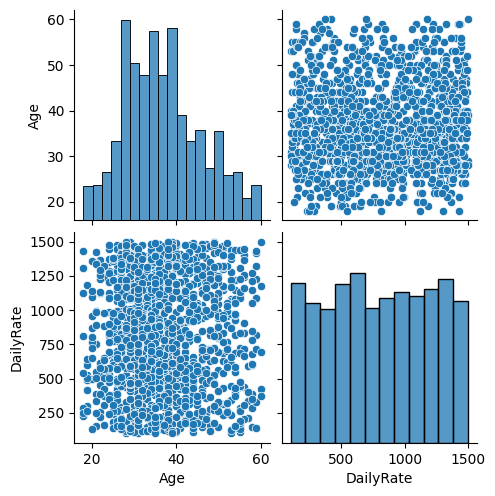

In [7]:
sns.pairplot(data1)

<Axes: >

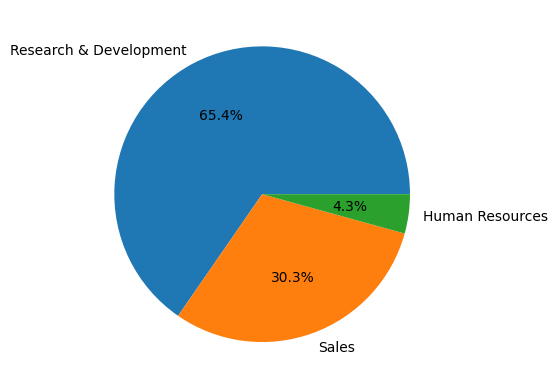

In [8]:
data1["Department"].value_counts().plot(kind="pie",autopct="%1.1f%%")

<Axes: >

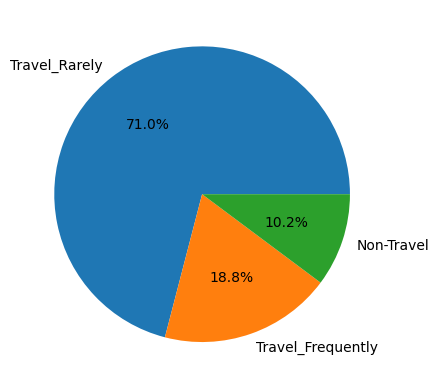

In [9]:
data1["BusinessTravel"].value_counts().plot(kind="pie",autopct="%1.1f%%")

<Axes: >

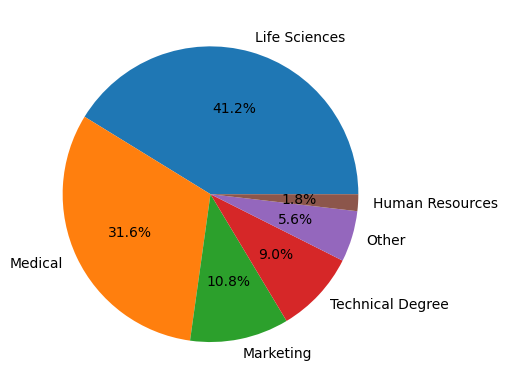

In [10]:
data["EducationField"].value_counts().plot(kind="pie",autopct="%1.1f%%")

<Axes: >

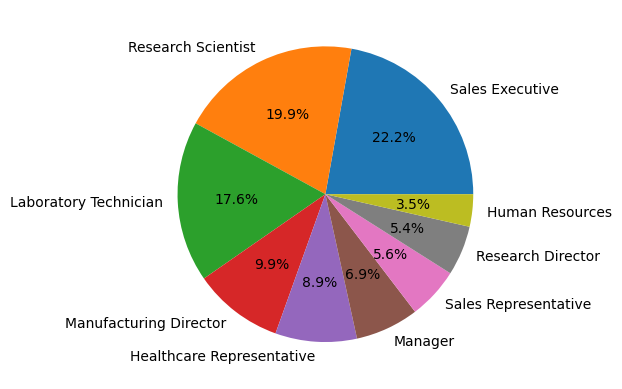

In [11]:
data["JobRole"].value_counts().plot(kind="pie",autopct="%1.1f%%")

<Axes: >

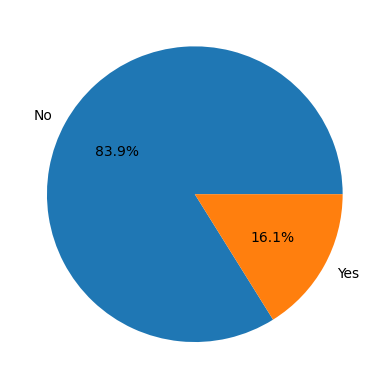

In [12]:
data1["Attrition"].value_counts().plot(kind="pie",autopct="%1.1f%%")

In [13]:
data3=pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv").drop(["OverTime","Attrition","JobRole","EducationField","Department","BusinessTravel","MaritalStatus","Gender","Over18"],axis=1)
data3.head(5)

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1102,1,2,1,1,2,94,3,2,...,1,80,0,8,0,1,6,4,0,5
1,49,279,8,1,1,2,3,61,2,2,...,4,80,1,10,3,3,10,7,1,7
2,37,1373,2,2,1,4,4,92,2,1,...,2,80,0,7,3,3,0,0,0,0
3,33,1392,3,4,1,5,4,56,3,1,...,3,80,0,8,3,3,8,7,3,0
4,27,591,2,1,1,7,1,40,3,1,...,4,80,1,6,3,3,2,2,2,2


In [14]:
dat_cor=data3.corr()

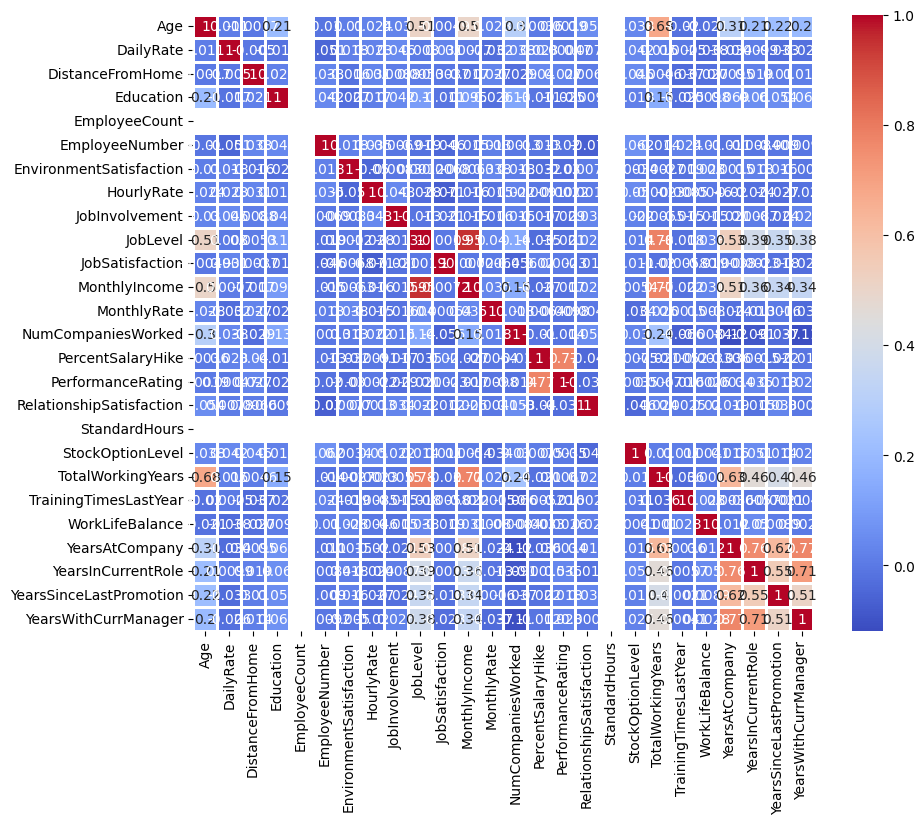

In [15]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(dat_cor, annot=True, fmt="0.2g", linewidths=1, cmap='coolwarm', square=False)
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)    
print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")
print("Training class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename(index={0: "No disease", 1: "Disease"}).to_frame("proportion"))

In [ ]:
numeric_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessing, numeric_features),
        ("categorical", categorical_preprocessing, categorical_features),
    ],
)



In [ ]:
model = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.0,
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
classifier = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", model),
])

classifier.fit(X_train, y_train)
print("Training complete.")
classifier